# Conditional one-output likelihood multi-task GP

### Introduction

In this tutorial we introduce the conditional one-output likelihood multi-task GP (Cool-MTGP). The notebook generates a synthetic dataset using and identical process to the one used in the paper. Both the hierarchical and approximate versions of the Cool-MTGP are demonstrated.

The first code cell deals with the imports needed to use our library.

In [23]:
# General imports

import numpy as np
import scipy as sp
from scipy.linalg import inv
from matplotlib import pyplot as plt
from mpl_toolkits.axes_grid1 import make_axes_locatable
from sklearn.metrics import mean_squared_error as MSE

# Import kernels for the Cool-MTGP model.
# We will only use linear kernels in this demo
from lib.kernels import DotProduct
from lib.kernels import WhiteKernel

# Import approximate Cool-MTGP (~Cool-MTGP)
from lib.A_Cool_MTGP import MultitaskGP as a_mtgp

# Import hierarchical Cool-MTGP (HCool-MTGP)
from lib.H_Cool_MTGP import MultitaskGP as h_mtgp

### Data generation

The data set is drawn from likelihood function $ p(\bf{y} | \bf{X}) = \mathcal{N}(\bf{y}|\bf{0},\bf{C}_{1:T,1:T}\otimes\bf{K} + \bf{\Sigma}_{1:T,1:T}\otimes\bf{I}) $, where $ \bf{K} = \bf{X}^\top \bf{X} $ and the intertask and noise covariance matrices follow the low rank form $ \bf{C}_{1:T,1:T} = \sum_{r=1}^R \bf{c}_r  \bf{c}_r^\top $ (and similarly for $ \bf{\Sigma}_{1:T,1:T} $). 

In [24]:
# GENERATE DATA

n_tr = 50          # number of training samples
n_tst = 30         # number of test samples
n_features = 25     # number of input dimensions
n_tasks = 5        # number of output tasks
rank = 5           # covariance matrix rank
noise_scale = 0.3   # output noise scale

n_samples = n_tr + n_tst
np.random.seed(None)

c = np.random.randn(n_tasks, rank)
s = np.random.randn(n_tasks, rank)
X = np.random.randn(n_samples, n_features)/np.sqrt(n_features)
K_X = np.dot(X, X.T)
C = np.dot(c, c.T)
Sigma = np.dot(s, s.T)*(noise_scale**2)
K_C = np.kron(C, K_X) 
K_Sigma = np.kron(Sigma, np.eye(n_samples))

y_signal = np.random.multivariate_normal(np.zeros(n_tasks*n_samples), K_C)
y_noise = np.random.multivariate_normal(np.zeros(n_tasks*n_samples), K_Sigma)
y = y_signal + y_noise
Y = np.reshape(y, (n_samples, n_tasks), order='F')

X_tr = X[:n_tr, :]
Y_tr = Y[:n_tr, :]
X_tst = X[n_tr:, :]
Y_tst = Y[n_tr:, :]

### Kernel definition

We will only use linear kernels for this example.

In [25]:
# Initialise kernels for the Cool-MTGP models

kernel_X = DotProduct(sigma_0=1, sigma_0_bounds="fixed")
kernel_noise = WhiteKernel(4, (1e-10, 100))

### Train the hierarchical Cool-MTGP

We use a similar API to that of scikit learn:
- An instance of the model is initialised. Input and noise kernels must be provided.
- The `fit()` method fits the model to a set of training data, X and Y train.
- The `predict()` method returns the predictive mean for a set of test data, X test.

The estimated versions of $\bf{C}$ and $\bf{\Sigma}$ are stored in `_PriorW` and `_SigmaTT` 

In [26]:
# HCOOL-MTGP

print('Training model...')
mtGP = h_mtgp(kernel=kernel_X, kernel_noise=kernel_noise, n_restarts_optimizer=15)
mtGP.fit(X_tr, Y_tr, alpha_method ='largeT')
print('Done.')

# Compute per-task covariances
C_hcool = mtGP._PriorW
Sigma_hcool = mtGP._SigmaTT

mean_hcool = mtGP.predict(X_tst, conf_intervals=False, compute_C_star=True)
error = Y_tst - mean_hcool
error_scale = np.dot(error.T, error)

Training model...
Done.


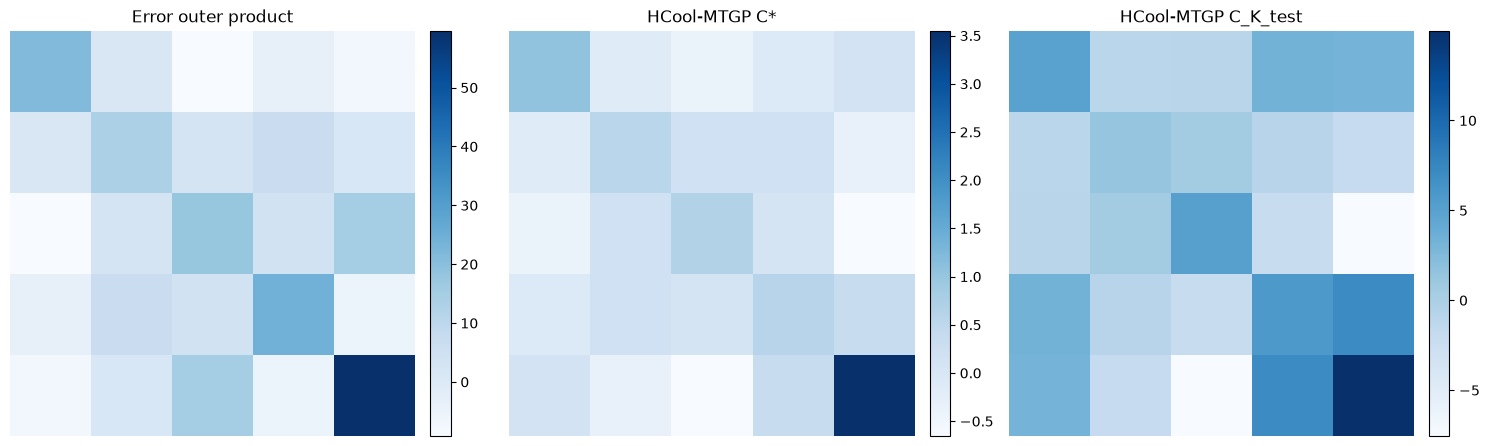

In [27]:
C_star = []
C_K_test = []
for i in range(n_tst):
    mean_hcool = mtGP.predict(X_tst[i, :].reshape((1, -1)), conf_intervals=False, compute_C_star=True)
    C_star.append(mtGP.C_star_)
    C_K_test.append(mtGP.C_K_test_)
    
fig, [ax1, ax2, ax3] = plt.subplots(1, 3, figsize=(15, 5))

C_plot = ax1.imshow(error_scale, cmap='Blues')
ax1.set_axis_off()
ax1.set_title('Error outer product')
divider = make_axes_locatable(ax1)
cax = divider.append_axes("right", size="5%", pad=pad)
plt.colorbar(C_plot, cax=cax)

C_plot = ax2.imshow(np.array(C_star).mean(axis=0), cmap='Blues')
ax2.set_axis_off()
ax2.set_title('HCool-MTGP C*')
divider = make_axes_locatable(ax2)
cax = divider.append_axes("right", size="5%", pad=pad)
plt.colorbar(C_plot, cax=cax)

C_plot = ax3.imshow(np.array(C_K_test).mean(axis=0), cmap='Blues')
ax3.set_axis_off()
ax3.set_title('HCool-MTGP C_K_test')
divider = make_axes_locatable(ax3)
cax = divider.append_axes("right", size="5%", pad=pad)
plt.colorbar(C_plot, cax=cax)

fig.tight_layout()

### Train the approximate Cool-MTGP

The API is identical to that of the hierarchical implementation. Training time is slightly faster.

In [28]:
# ~COOL-MTGP

print('Training model...')
mtGP = a_mtgp(kernel=kernel_X, kernel_noise=kernel_noise, n_restarts_optimizer=15)
mtGP.fit(X_tr, Y_tr)
mean_acool = mtGP.predict(X_tst, conf_intervals=False)

# Compute per-task covariances
C_acool = mtGP._PriorW
Sigma_acool = mtGP._SigmaTT

mse = MSE(Y_tst, mean_acool)
print(f'\nModel mean square error = {mse:.2f}')

Training model...

Model mean square error = 0.88


### Visualization

We can now visually compare the estimated $\bf{C}$ and $\bf{\Sigma}$ matrices with their true values for both implementations.

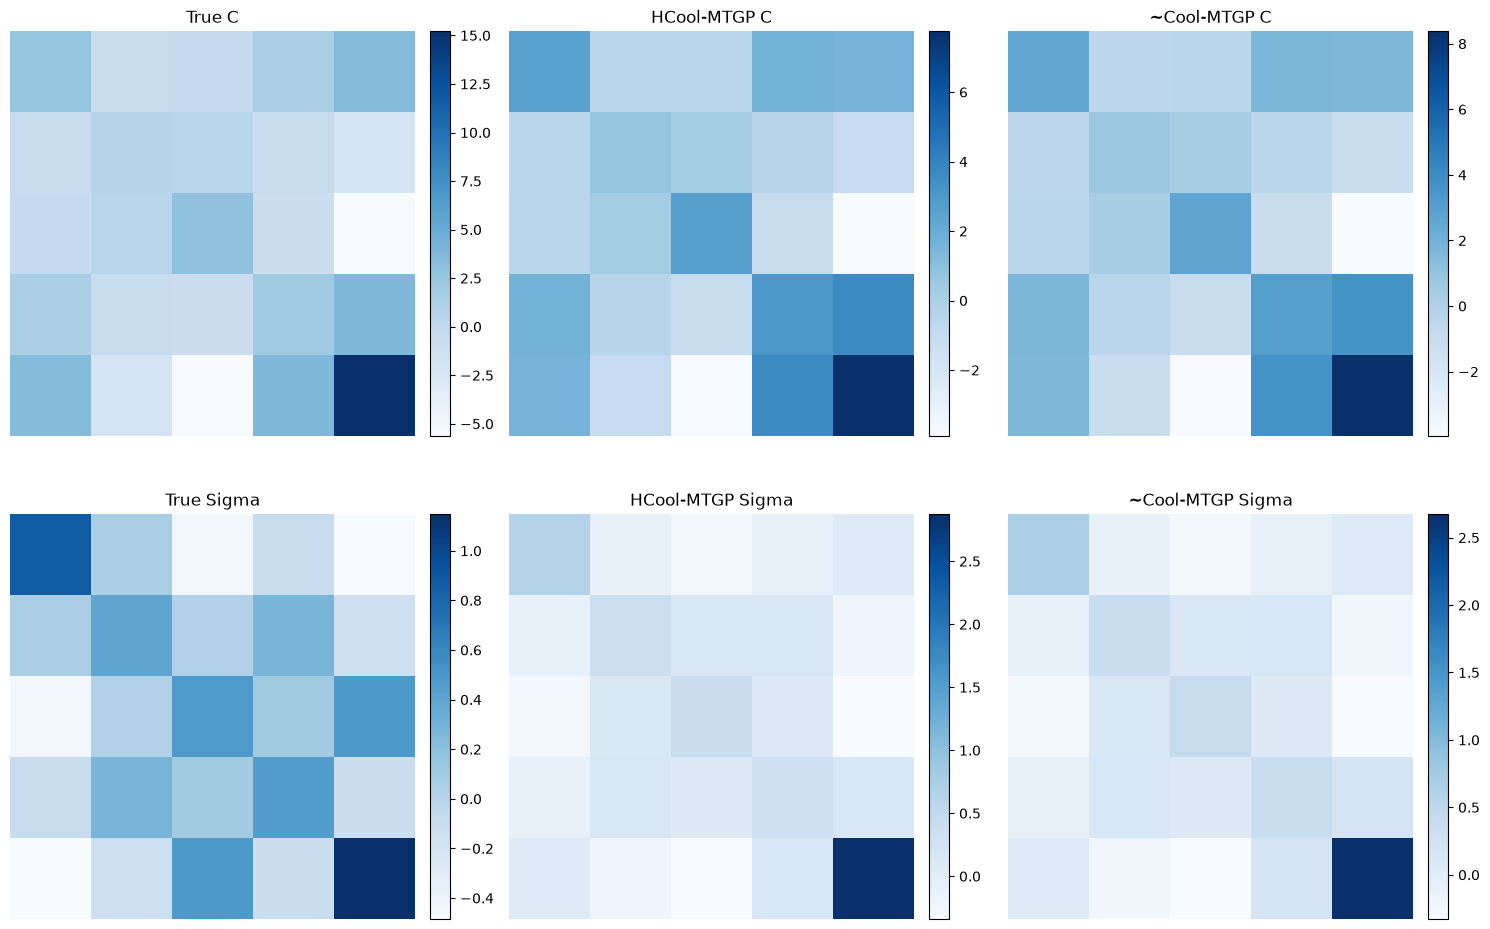

In [29]:
# Plot matrices
pad=0.15

fig, [[ax1, ax2, ax3], [ax4, ax5, ax6]] = plt.subplots(2, 3, figsize=(15, 10))

C_plot = ax1.imshow(C, cmap='Blues')
ax1.set_axis_off()
ax1.set_title('True C')
divider = make_axes_locatable(ax1)
cax = divider.append_axes("right", size="5%", pad=pad)
plt.colorbar(C_plot, cax=cax)

C_plot = ax2.imshow(C_hcool, cmap='Blues')
ax2.set_axis_off()
ax2.set_title('HCool-MTGP C')
divider = make_axes_locatable(ax2)
cax = divider.append_axes("right", size="5%", pad=pad)
plt.colorbar(C_plot, cax=cax)

C_plot = ax3.imshow(C_acool, cmap='Blues')
ax3.set_axis_off()
ax3.set_title('~Cool-MTGP C')
divider = make_axes_locatable(ax3)
cax = divider.append_axes("right", size="5%", pad=pad)
plt.colorbar(C_plot, cax=cax)

Sigma_plot = ax4.imshow(Sigma, cmap='Blues')
ax4.set_axis_off()
ax4.set_title('True Sigma')
divider = make_axes_locatable(ax4)
cax = divider.append_axes("right", size="5%", pad=pad)
plt.colorbar(Sigma_plot, cax=cax)

Sigma_plot = ax5.imshow(Sigma_hcool, cmap='Blues')
ax5.set_axis_off()
ax5.set_title('HCool-MTGP Sigma')
divider = make_axes_locatable(ax5)
cax = divider.append_axes("right", size="5%", pad=pad)
plt.colorbar(Sigma_plot, cax=cax)

Sigma_plot = ax6.imshow(Sigma_acool, cmap='Blues')
ax6.set_axis_off()
ax6.set_title('~Cool-MTGP Sigma')
divider = make_axes_locatable(ax6)
cax = divider.append_axes("right", size="5%", pad=pad)
plt.colorbar(Sigma_plot, cax=cax)

fig.tight_layout()